In [10]:
from sklearn.datasets import load_breast_cancer

breast_cancer_data = load_breast_cancer()
print(breast_cancer_data.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [1]:
pip install PyMuPDF

     -------------------------------------- 18.7/18.7 MB 916.4 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Admin\Desktop\ML projects\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [6]:
import fitz

def remove_watermark(input_pdf, output_pdf):
    # فتح الملف الأصلي
    doc = fitz.open(input_pdf)
    
    print(f"Processing '{input_pdf}' ({len(doc)} pages)...")
    
    for page_num, page in enumerate(doc):
        # البحث عن العلامة المائية "محمود علاء"
        text_instances = page.search_for("محمود علاء")
        
        for inst in text_instances:
            # إضافة مستطيل إخفاء فوق كل مكان تظهر فيه العلامة المائية
            page.add_redact_rect(inst)
            
        # تطبيق المسح على الصفحة
        page.apply_redactions()
        
    # حفظ الملف الناتج في مسار/اسم مختلف عشان الملف الأصلي يفضل سليم
    doc.save(output_pdf, garbage=4, deflate=True)
    doc.close()
    print(f"Successfully saved cleaned PDF to: {output_pdf}")

if __name__ == "__main__":
    # المسارات بتتحدد هنا بس تحت عند الاستدعاء
    input_file = r"C:\Users\Admin\Desktop\كتاب البكالوريا_Optimized(1).pdf"
    output_file = r"C:\Users\Admin\Desktop\كتاب_البكالوريا_Cleaned.pdf"
    
    remove_watermark(input_file, output_file)

Processing 'C:\Users\Admin\Desktop\كتاب البكالوريا_Optimized(1).pdf' (621 pages)...
Successfully saved cleaned PDF to: C:\Users\Admin\Desktop\كتاب_البكالوريا_Cleaned.pdf


In [7]:
pip install pdf2image pillow

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Admin\Desktop\ML projects\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [ ]:
import fitz  # PyMuPDF

def rasterize_and_clean(input_pdf, output_pdf):
    doc = fitz.open(input_pdf)
    new_doc = fitz.open() # ملف PDF جديد فارغ

    print(f"جاري معالجة {len(doc)} صفحة...")

    for page_num, page in enumerate(doc):
        # تحويل الصفحة لصورة عالية الدقة (DPI 300) عشان الجودة ما تقلش
        pix = page.get_pixmap(dpi=300)
        img_data = pix.tobytes("png")

        # إنشاء صفحة جديدة بنفس مقاسات الصفحة القديمة وإدراج الصورة كخلفية صافية
        # (هنا بنطبع الصفحة كصورة "مفلطحة" Flattened متطيرة منها أي طبقات نصية علوية)
        new_page = new_doc.new_page(width=page.rect.width, height=page.rect.height)
        new_page.insert_image(new_page.rect, stream=img_data)

    new_doc.save(output_pdf)
    new_doc.close()
    doc.close()
    print("تم إنتاج النسخة النضيفة بنجاح!")

if __name__ == "__main__":
    rasterize_and_clean(
        r"C:\Users\Admin\Desktop\كتاب البكالوريا_Optimized(1).pdf",
        r"C:\Users\Admin\Desktop\كتاب_البكالوريا_Cleaned_Flat.pdf"
    )

جاري معالجة 621 صفحة...


In [9]:
pip install scikit-learn

     ---------------------------------------- 11.2/11.2 MB 1.6 MB/s eta 0:00:00
     -------------------------------------- 15.9/15.9 MB 795.2 kB/s eta 0:00:00
     ---------------------------------------- 46.2/46.2 MB 1.6 MB/s eta 0:00:00
     -------------------------------------- 309.1/309.1 KB 1.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Admin\Desktop\ML projects\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [13]:
import pandas as pd

df = pd.DataFrame(data=breast_cancer_data.data, columns=breast_cancer_data.feature_names)
print(df.head())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

In [12]:
pip install pandas

     ---------------------------------------- 11.4/11.4 MB 1.6 MB/s eta 0:00:00
     -------------------------------------- 508.3/508.3 KB 1.6 MB/s eta 0:00:00
     -------------------------------------- 347.5/347.5 KB 1.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Admin\Desktop\ML projects\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [ ]:
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [14]:
from sklearn.model_selection import train_test_split

X = df
y = breast_cancer_data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (455, 30)
X_test shape: (114, 30)
y_train shape: (455,)
y_test shape: (114,)


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Initialize the Logistic Regression model
model = LogisticRegression(random_state=42, solver='liblinear') # Using 'liblinear' solver for small datasets and binary classification

# Train the model
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model's accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Logistic Regression Model Accuracy: {accuracy:.4f}")

Logistic Regression Model Accuracy: 0.9561


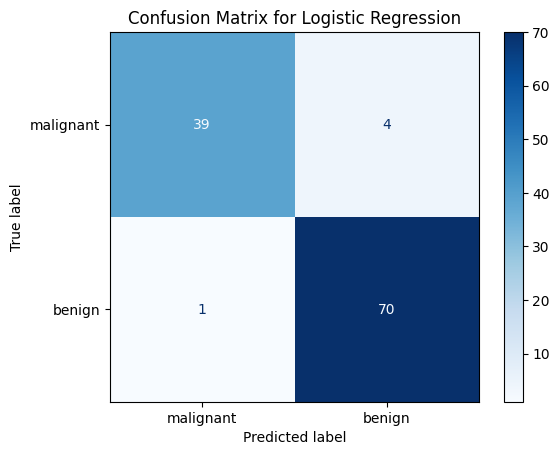

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=breast_cancer_data.target_names)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for Logistic Regression')
plt.show()

In [17]:
pip install matplotlib


     ---------------------------------------- 7.8/7.8 MB 1.6 MB/s eta 0:00:00
     ---------------------------------------- 7.0/7.0 MB 1.6 MB/s eta 0:00:00
     -------------------------------------- 211.8/211.8 KB 1.4 MB/s eta 0:00:00
     -------------------------------------- 122.8/122.8 KB 1.8 MB/s eta 0:00:00
     ---------------------------------------- 1.5/1.5 MB 1.6 MB/s eta 0:00:00
     ---------------------------------------- 55.8/55.8 KB 1.5 MB/s eta 0:00:00


You should consider upgrading via the 'c:\Users\Admin\Desktop\ML projects\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


In [19]:
from sklearn.metrics import classification_report

# Generate and print the classification report
report = classification_report(y_test, y_pred, target_names=breast_cancer_data.target_names)
print(report)

              precision    recall  f1-score   support

   malignant       0.97      0.91      0.94        43
      benign       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [20]:
from sklearn.metrics import classification_report

# Make predictions on the training set
y_train_pred = model.predict(X_train)

# Generate and print the classification report for the training data
report_train = classification_report(y_train, y_train_pred, target_names=breast_cancer_data.target_names)
print(report_train)

              precision    recall  f1-score   support

   malignant       0.96      0.93      0.94       169
      benign       0.96      0.98      0.97       286

    accuracy                           0.96       455
   macro avg       0.96      0.95      0.96       455
weighted avg       0.96      0.96      0.96       455



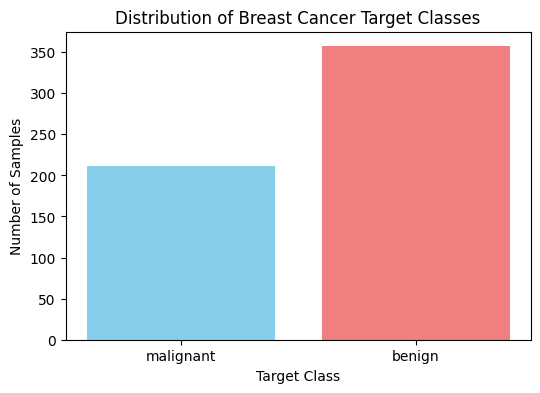

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Get unique values and their counts from the target variable
unique_targets, counts = np.unique(breast_cancer_data.target, return_counts=True)

# Get target names for labeling
target_names = breast_cancer_data.target_names

# Create the bar plot
plt.figure(figsize=(6, 4))
plt.bar(target_names, counts, color=['skyblue', 'lightcoral'])
plt.xlabel('Target Class')
plt.ylabel('Number of Samples')
plt.title('Distribution of Breast Cancer Target Classes')
plt.show()

### Applying SMOTE for Augmentation

Since we saw some class imbalance in the target variable, we'll apply SMOTE (Synthetic Minority Oversampling Technique) to the training data. This will create synthetic samples of the minority class to balance the dataset, potentially improving model performance.

In [24]:
from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply SMOTE to the training data
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f"Original training data shape: {X_train.shape, y_train.shape}")
print(f"SMOTE augmented training data shape: {X_train_smote.shape, y_train_smote.shape}")

c:\Users\Admin\Desktop\ML projects\.venv\lib\site-packages\sklearn\base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


Original training data shape: ((455, 30), (455,))
SMOTE augmented training data shape: ((572, 30), (572,))


In [23]:
pip install imblearn

     ------------------------------------ 258.3/258.3 KB 992.3 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\Admin\Desktop\ML projects\.venv\Scripts\python.exe -m pip install --upgrade pip' command.


Now, let's retrain the Logistic Regression model using the SMOTE-augmented training data and re-evaluate its performance.

Logistic Regression Model Accuracy (with SMOTE): 0.9649

Classification Report (Test Data with SMOTE):
               precision    recall  f1-score   support

   malignant       0.98      0.93      0.95        43
      benign       0.96      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



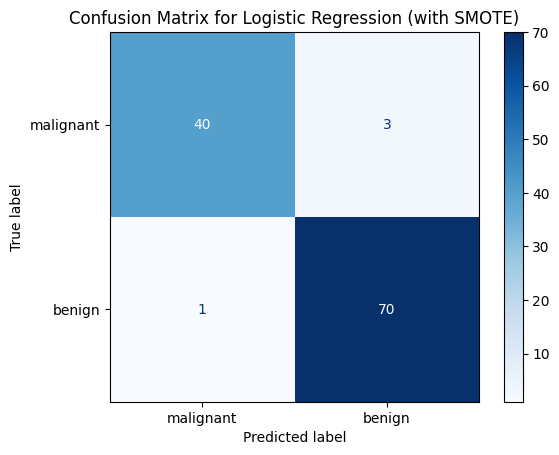

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Initialize the Logistic Regression model again
model_smote = LogisticRegression(random_state=42, solver='liblinear')

# Train the model with SMOTE augmented data
model_smote.fit(X_train_smote, y_train_smote)

# Make predictions on the test set (original test set, not augmented)
y_pred_smote = model_smote.predict(X_test)

# Evaluate the model's accuracy
accuracy_smote = accuracy_score(y_test, y_pred_smote)
print(f"Logistic Regression Model Accuracy (with SMOTE): {accuracy_smote:.4f}")

# Generate and print the classification report for the test data
report_smote = classification_report(y_test, y_pred_smote, target_names=breast_cancer_data.target_names)
print("\nClassification Report (Test Data with SMOTE):\n", report_smote)

# Calculate and display the confusion matrix for the test data
cm_smote = confusion_matrix(y_test, y_pred_smote)
disp_smote = ConfusionMatrixDisplay(confusion_matrix=cm_smote, display_labels=breast_cancer_data.target_names)
disp_smote.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for Logistic Regression (with SMOTE)')
plt.show()

Let's also check the classification report for the SMOTE augmented *training* data to see the effect of oversampling.

In [26]:
# Make predictions on the SMOTE augmented training set
y_train_pred_smote = model_smote.predict(X_train_smote)

# Generate and print the classification report for the SMOTE augmented training data
report_train_smote = classification_report(y_train_smote, y_train_pred_smote, target_names=breast_cancer_data.target_names)
print("Classification Report (SMOTE Augmented Training Data):\n", report_train_smote)

Classification Report (SMOTE Augmented Training Data):
               precision    recall  f1-score   support

   malignant       0.97      0.95      0.96       286
      benign       0.95      0.97      0.96       286

    accuracy                           0.96       572
   macro avg       0.96      0.96      0.96       572
weighted avg       0.96      0.96      0.96       572



Linear Support Vector Machine Model Accuracy (with SMOTE): 0.8333

Classification Report (Test Data for Linear SVC with SMOTE):
               precision    recall  f1-score   support

   malignant       1.00      0.56      0.72        43
      benign       0.79      1.00      0.88        71

    accuracy                           0.83       114
   macro avg       0.89      0.78      0.80       114
weighted avg       0.87      0.83      0.82       114



c:\Users\Admin\Desktop\ML projects\.venv\lib\site-packages\sklearn\svm\_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


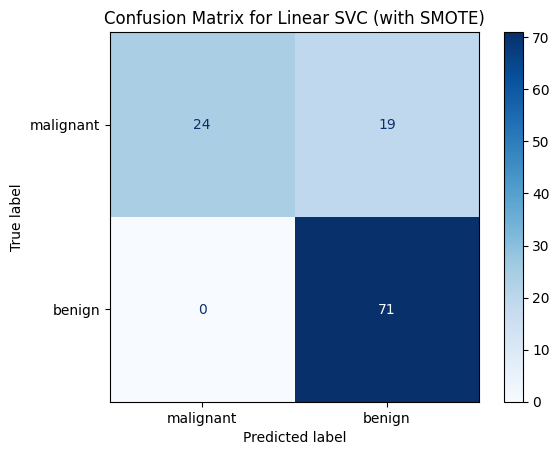

In [27]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Initialize the LinearSVC model
# Set dual=False when n_samples > n_features for better performance and convergence
# Set max_iter for convergence as it might take many iterations for some datasets
linear_svc_model = LinearSVC(random_state=42, dual=True, max_iter=2000)

# Train the model with SMOTE augmented data
linear_svc_model.fit(X_train_smote, y_train_smote)

# Make predictions on the test set (original test set, not augmented)
y_pred_linear_svc = linear_svc_model.predict(X_test)

# Evaluate the model's accuracy
accuracy_linear_svc = accuracy_score(y_test, y_pred_linear_svc)
print(f"Linear Support Vector Machine Model Accuracy (with SMOTE): {accuracy_linear_svc:.4f}")

# Generate and print the classification report for the test data
report_linear_svc = classification_report(y_test, y_pred_linear_svc, target_names=breast_cancer_data.target_names)
print("\nClassification Report (Test Data for Linear SVC with SMOTE):\n", report_linear_svc)

# Calculate and display the confusion matrix for the test data
cm_linear_svc = confusion_matrix(y_test, y_pred_linear_svc)
disp_linear_svc = ConfusionMatrixDisplay(confusion_matrix=cm_linear_svc, display_labels=breast_cancer_data.target_names)
disp_linear_svc.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for Linear SVC (with SMOTE)')
plt.show()

Linear Support Vector Machine Model Accuracy (without SMOTE): 0.9561

Classification Report (Test Data for Linear SVC without SMOTE):
               precision    recall  f1-score   support

   malignant       0.97      0.91      0.94        43
      benign       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



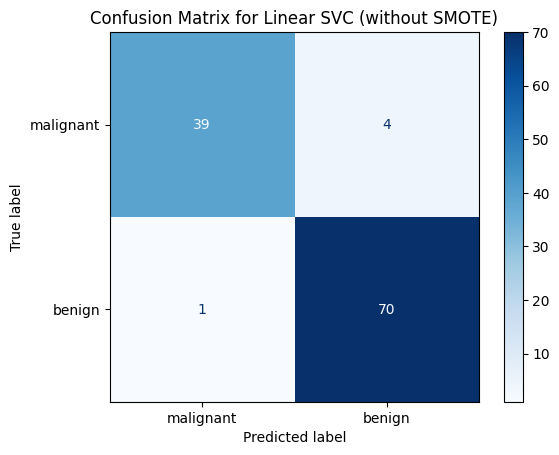

In [28]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Initialize the LinearSVC model
# Set dual=True for n_samples < n_features, or dual=False for n_samples > n_features
# Given X_train shape is (455, 30), n_samples > n_features, so dual=False is generally preferred
# However, to avoid 'ConvergenceWarning', increasing max_iter is also important.
# For this dataset, dual=True with higher max_iter might also work, but dual=False is often faster when n_samples > n_features
# Let's use dual=False for this case as n_samples (455) > n_features (30)
linear_svc_model_no_smote = LinearSVC(random_state=42, dual=False, max_iter=5000)

# Train the model with original training data (without SMOTE)
linear_svc_model_no_smote.fit(X_train, y_train)

# Make predictions on the test set
y_pred_linear_svc_no_smote = linear_svc_model_no_smote.predict(X_test)

# Evaluate the model's accuracy
accuracy_linear_svc_no_smote = accuracy_score(y_test, y_pred_linear_svc_no_smote)
print(f"Linear Support Vector Machine Model Accuracy (without SMOTE): {accuracy_linear_svc_no_smote:.4f}")

# Generate and print the classification report for the test data
report_linear_svc_no_smote = classification_report(y_test, y_pred_linear_svc_no_smote, target_names=breast_cancer_data.target_names)
print("\nClassification Report (Test Data for Linear SVC without SMOTE):\n", report_linear_svc_no_smote)

# Calculate and display the confusion matrix for the test data
cm_linear_svc_no_smote = confusion_matrix(y_test, y_pred_linear_svc_no_smote)
disp_linear_svc_no_smote = ConfusionMatrixDisplay(confusion_matrix=cm_linear_svc_no_smote, display_labels=breast_cancer_data.target_names)
disp_linear_svc_no_smote.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for Linear SVC (without SMOTE)')
plt.show()


--- Support Vector Machine with Polynomial Kernel ---
Accuracy (Polynomial Kernel): 0.9474
Classification Report (Polynomial Kernel):
               precision    recall  f1-score   support

   malignant       1.00      0.86      0.93        43
      benign       0.92      1.00      0.96        71

    accuracy                           0.95       114
   macro avg       0.96      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114



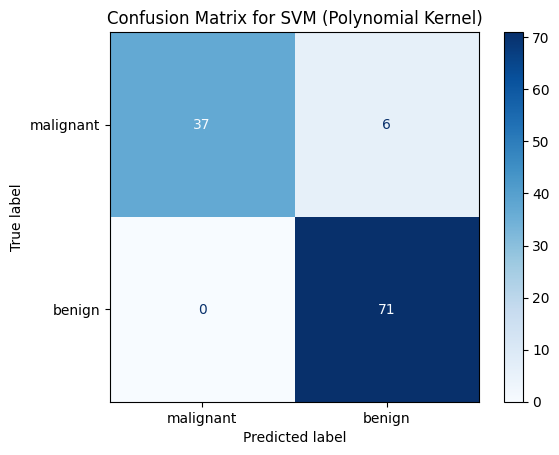


--- Support Vector Machine with RBF Kernel ---
Accuracy (RBF Kernel): 0.9474
Classification Report (RBF Kernel):
               precision    recall  f1-score   support

   malignant       1.00      0.86      0.93        43
      benign       0.92      1.00      0.96        71

    accuracy                           0.95       114
   macro avg       0.96      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114



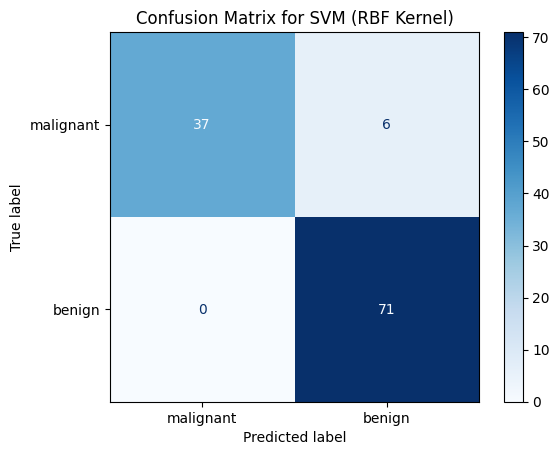


--- Support Vector Machine with Sigmoid Kernel ---
Accuracy (Sigmoid Kernel): 0.4649
Classification Report (Sigmoid Kernel):
               precision    recall  f1-score   support

   malignant       0.20      0.14      0.16        43
      benign       0.56      0.66      0.61        71

    accuracy                           0.46       114
   macro avg       0.38      0.40      0.39       114
weighted avg       0.42      0.46      0.44       114



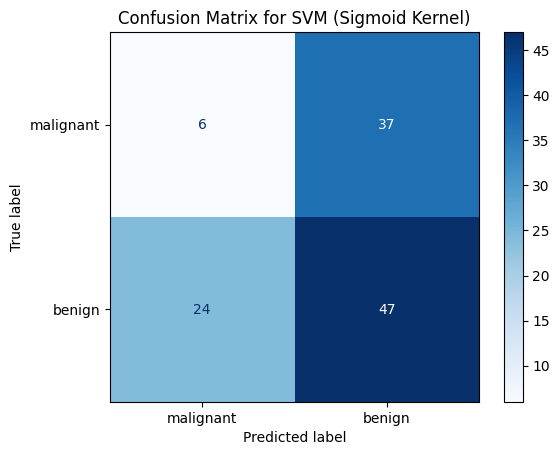

In [29]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# --- SVM with Polynomial Kernel ---
print("\n--- Support Vector Machine with Polynomial Kernel ---")
svm_poly = SVC(kernel='poly', degree=3, random_state=42)
svm_poly.fit(X_train, y_train)
y_pred_poly = svm_poly.predict(X_test)

accuracy_poly = accuracy_score(y_test, y_pred_poly)
print(f"Accuracy (Polynomial Kernel): {accuracy_poly:.4f}")
print("Classification Report (Polynomial Kernel):\n", classification_report(y_test, y_pred_poly, target_names=breast_cancer_data.target_names))

cm_poly = confusion_matrix(y_test, y_pred_poly)
disp_poly = ConfusionMatrixDisplay(confusion_matrix=cm_poly, display_labels=breast_cancer_data.target_names)
disp_poly.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for SVM (Polynomial Kernel)')
plt.show()

# --- SVM with Radial Basis Function (RBF) Kernel ---
print("\n--- Support Vector Machine with RBF Kernel ---")
svm_rbf = SVC(kernel='rbf', random_state=42)
svm_rbf.fit(X_train, y_train)
y_pred_rbf = svm_rbf.predict(X_test)

accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
print(f"Accuracy (RBF Kernel): {accuracy_rbf:.4f}")
print("Classification Report (RBF Kernel):\n", classification_report(y_test, y_pred_rbf, target_names=breast_cancer_data.target_names))

cm_rbf = confusion_matrix(y_test, y_pred_rbf)
disp_rbf = ConfusionMatrixDisplay(confusion_matrix=cm_rbf, display_labels=breast_cancer_data.target_names)
disp_rbf.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for SVM (RBF Kernel)')
plt.show()

# --- SVM with Sigmoid Kernel ---
print("\n--- Support Vector Machine with Sigmoid Kernel ---")
svm_sigmoid = SVC(kernel='sigmoid', random_state=42)
svm_sigmoid.fit(X_train, y_train)
y_pred_sigmoid = svm_sigmoid.predict(X_test)

accuracy_sigmoid = accuracy_score(y_test, y_pred_sigmoid)
print(f"Accuracy (Sigmoid Kernel): {accuracy_sigmoid:.4f}")
print("Classification Report (Sigmoid Kernel):\n", classification_report(y_test, y_pred_sigmoid, target_names=breast_cancer_data.target_names))

cm_sigmoid = confusion_matrix(y_test, y_pred_sigmoid)
disp_sigmoid = ConfusionMatrixDisplay(confusion_matrix=cm_sigmoid, display_labels=breast_cancer_data.target_names)
disp_sigmoid.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for SVM (Sigmoid Kernel)')
plt.show()

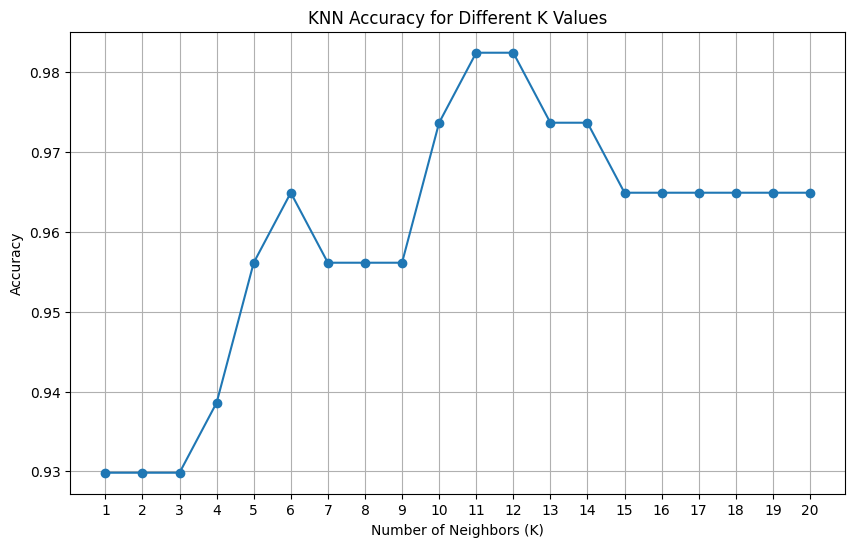


Best K value: 11
Best Accuracy for K=11: 0.9825

--- K-Nearest Neighbors Model with best K=11 ---
KNN Model Accuracy (best K=11): 0.9825
Classification Report (KNN with best K):
               precision    recall  f1-score   support

   malignant       1.00      0.95      0.98        43
      benign       0.97      1.00      0.99        71

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



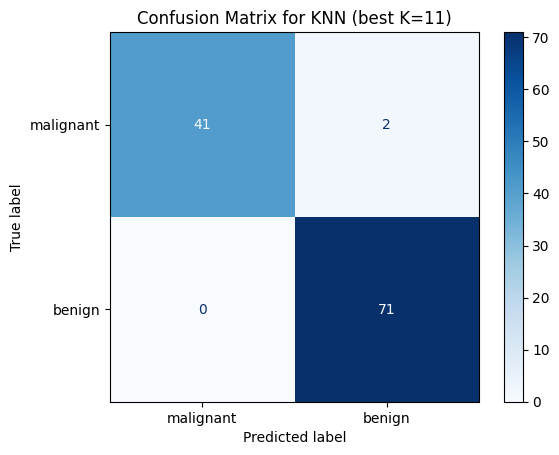

In [30]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# --- Finding the best K value ---
accuracies = []
k_values = range(1, 21) # Test k from 1 to 20

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    y_pred_knn = knn.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred_knn))

# Plotting the accuracy curve
plt.figure(figsize=(10, 6))
plt.plot(k_values, accuracies, marker='o', linestyle='-')
plt.title('KNN Accuracy for Different K Values')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.grid(True)
plt.show()

# Find the best K and its accuracy
best_k_index = np.argmax(accuracies)
best_k = k_values[best_k_index]
best_accuracy = accuracies[best_k_index]

print(f"\nBest K value: {best_k}")
print(f"Best Accuracy for K={best_k}: {best_accuracy:.4f}")

# --- Train and Evaluate KNN with the best K ---
print(f"\n--- K-Nearest Neighbors Model with best K={best_k} ---")
best_knn_model = KNeighborsClassifier(n_neighbors=best_k)
best_knn_model.fit(X_train, y_train)
y_pred_best_knn = best_knn_model.predict(X_test)

accuracy_best_knn = accuracy_score(y_test, y_pred_best_knn)
print(f"KNN Model Accuracy (best K={best_k}): {accuracy_best_knn:.4f}")

report_best_knn = classification_report(y_test, y_pred_best_knn, target_names=breast_cancer_data.target_names)
print("Classification Report (KNN with best K):\n", report_best_knn)

cm_best_knn = confusion_matrix(y_test, y_pred_best_knn)
disp_best_knn = ConfusionMatrixDisplay(confusion_matrix=cm_best_knn, display_labels=breast_cancer_data.target_names)
disp_best_knn.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix for KNN (best K={best_k})')
plt.show()

Decision Tree Classifier Model Accuracy (with SMOTE): 0.9737

Classification Report (Test Data for Decision Tree with SMOTE):
               precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        43
      benign       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



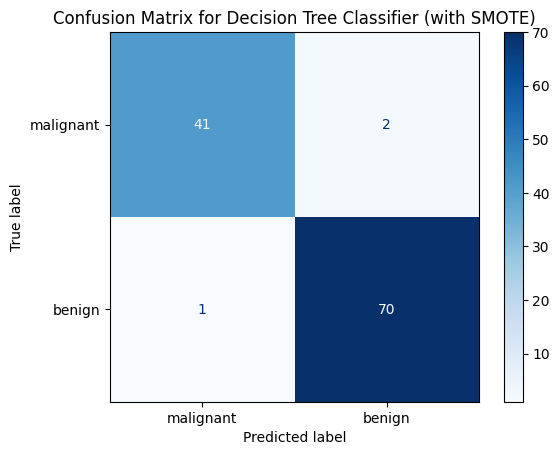

In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Initialize the Decision Tree Classifier
dtc_model = DecisionTreeClassifier(random_state=42,max_depth=3)

# Train the model with SMOTE augmented data
dtc_model.fit(X_train_smote, y_train_smote)

# Make predictions on the test set (original test set, not augmented)
y_pred_dtc = dtc_model.predict(X_test)

# Evaluate the model's accuracy
accuracy_dtc = accuracy_score(y_test, y_pred_dtc)
print(f"Decision Tree Classifier Model Accuracy (with SMOTE): {accuracy_dtc:.4f}")

# Generate and print the classification report for the test data
report_dtc = classification_report(y_test, y_pred_dtc, target_names=breast_cancer_data.target_names)
print("\nClassification Report (Test Data for Decision Tree with SMOTE):\n", report_dtc)

# Calculate and display the confusion matrix for the test data
cm_dtc = confusion_matrix(y_test, y_pred_dtc)
disp_dtc = ConfusionMatrixDisplay(confusion_matrix=cm_dtc, display_labels=breast_cancer_data.target_names)
disp_dtc.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix for Decision Tree Classifier (with SMOTE)')
plt.show()